# Praktikum 2: Klasifikasi Multilabel dengan Dataset CIFAR-10 Menggunakan CNN

* **Mata Kuliah**: Pembelajaran Mesin (RTI235004)
* **Topik Modul**: JS14 - Convolutional Neural Network
* **Nama**: Mohammad Al Hafis Hidayatulloh
* **NIM**: 254107023005
* **Kelas**: TI-3G

---

### Deskripsi Praktikum
Pada praktikum ini, kita membangun model Convolutional Neural Network (CNN) dasar untuk mengklasifikasikan citra berwarna dari dataset **CIFAR-10** ke dalam 10 kategori objek. Dataset CIFAR-10 terdiri dari total 60.000 citra berdimensi $32 \times 32$ piksel dengan 3 kanal warna (RGB), yang telah dibagi menjadi 50.000 data latih (*training images*) dan 10.000 data uji (*test images*).

10 kategori objek pada CIFAR-10 meliputi: `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, dan `truck`.


### Langkah 1 - Load Library
Mengimpor pustaka TensorFlow, Keras Datasets, Layers, Models, serta Matplotlib untuk visualisasi.


In [1]:
import os, time
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# Load helper kompatibilitas lokal jika tersedia
try:
    import cnn_compat
except ImportError:
    pass

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.21.0


### Langkah 2 - Unduh dan Normalisasi Dataset CIFAR-10
Memuat dataset CIFAR-10 dan melakukan normalisasi nilai piksel citra dari interval $[0, 255]$ ke interval $[0.0, 1.0]$ dengan membaginya dengan 255.0.


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

print(f"Jumlah Citra Latih : {train_images.shape[0]} citra, dimensi: {train_images.shape[1:]}")
print(f"Jumlah Citra Uji   : {test_images.shape[0]} citra, dimensi: {test_images.shape[1:]}")
print(f"Bentuk Label Latih : {train_labels.shape}")


Jumlah Citra Latih : 50000 citra, dimensi: (32, 32, 3)
Jumlah Citra Uji   : 10000 citra, dimensi: (32, 32, 3)
Bentuk Label Latih : (50000, 1)


### Langkah 3 - Verifikasi Data
Menampilkan 25 sampel citra pertama dari himpunan data latih dalam format grid $5 \times 5$ lengkap dengan label nama kelas untuk memverifikasi kesesuaian data.


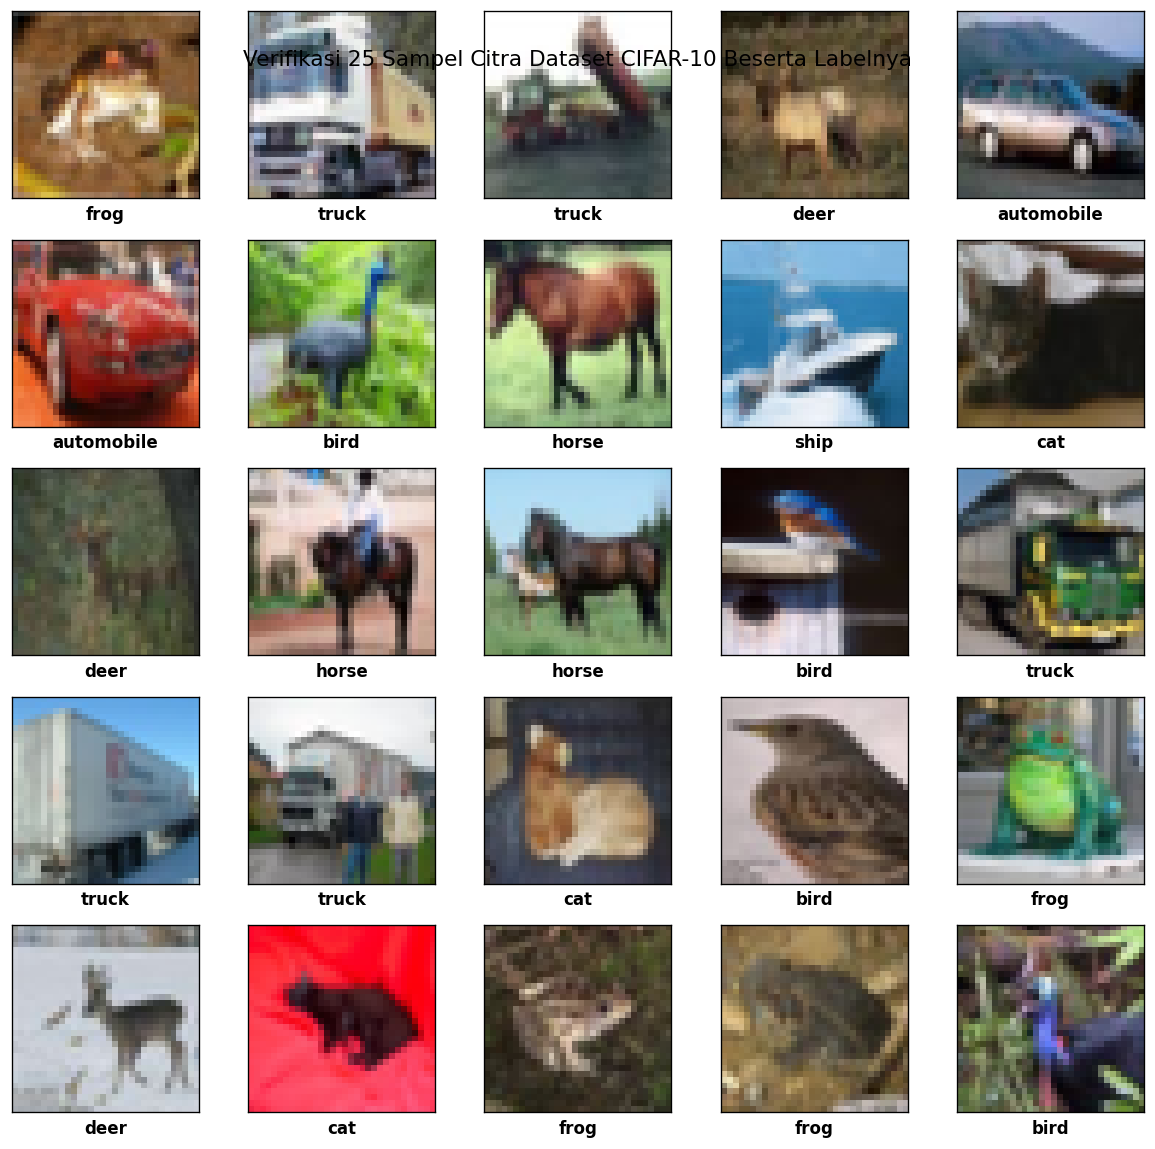

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays, which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]], fontsize=10, fontweight='bold')

plt.suptitle("Verifikasi 25 Sampel Citra Dataset CIFAR-10 Beserta Labelnya", fontsize=13, y=0.92)
plt.tight_layout()
plt.show()


### Langkah 4 - Pembuatan Arsitektur Model CNN
Arsitektur dasar CNN dibangun dengan komponen:
* **Blok Konvolusi**:
  1. `Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3))`
  2. `MaxPooling2D((2, 2))`
  3. `Conv2D(64, (3, 3), activation='relu')`
  4. `MaxPooling2D((2, 2))`
  5. `Conv2D(64, (3, 3), activation='relu')`
* **Blok Fully Connected (Dense)**:
  1. `Flatten()`
  2. `Dense(64, activation='relu')`
  3. `Dense(10)` (output logits untuk 10 kelas)


In [4]:
# Langkah 4.1 & 4.3 - Membangun Model Sequential
model = models.Sequential()

# Blok Konvolusi
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Blok Klasifikasi (Dense)
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

# Langkah 4.4 - Cek Ringkasan Arsitektur Model
model.summary()


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼─────────────────────

### Langkah 4.5 - Kompilasi Model CNN
Model dikompilasi menggunakan optimizer Adam dan `SparseCategoricalCrossentropy(from_logits=True)` karena label berupa integer skalar [0-9] dan output layer terakhir berupa logits tanpa aktivasi softmax.


In [5]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)


### Langkah 5 - Pelatihan Model (Fit Model)
Melatih model selama 10 epoch dengan mengevaluasi performanya pada `test_images` dan `test_labels` di setiap akhir epoch.


In [6]:
t_start = time.time()
history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(test_images, test_labels)
)
duration = time.time() - t_start
print(f"\nPelatihan model CNN CIFAR-10 selesai dalam {duration:.2f} detik.")


Epoch 1/10

  1/782 ━━━━━━━━━━━━━━━━━━━━ 28:12 2s/step - accuracy: 0.0938 - loss: 2.3022
  3/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.0955 - loss: 2.3136
  5/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.1046 - loss: 2.3110
  7/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.1067 - loss: 2.3103
  9/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.1075 - loss: 2.3098
 11/782 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.1086 - loss: 2.3088
 13/782 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.1115 - loss: 2.3073
 15/782 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.1136 - loss: 2.3057
 17/782 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.1148 - loss: 2.3042
 19/782 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.1163 - loss: 2.3023
 20/782 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.1169 - loss: 2.3014
 22/782 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.1184 - loss: 2.2993
 23/782 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.1191 - 

### Langkah 6 - Evaluasi Model dan Visualisasi Hasil Pelatihan
Membuat grafik kurva akurasi pelatihan (*training accuracy*) vs akurasi validasi (*validation accuracy*) sepanjang 10 epoch, serta menghitung metrik evaluasi final pada data uji.


313/313 - 2s - 7ms/step - accuracy: 0.7104 - loss: 0.8553


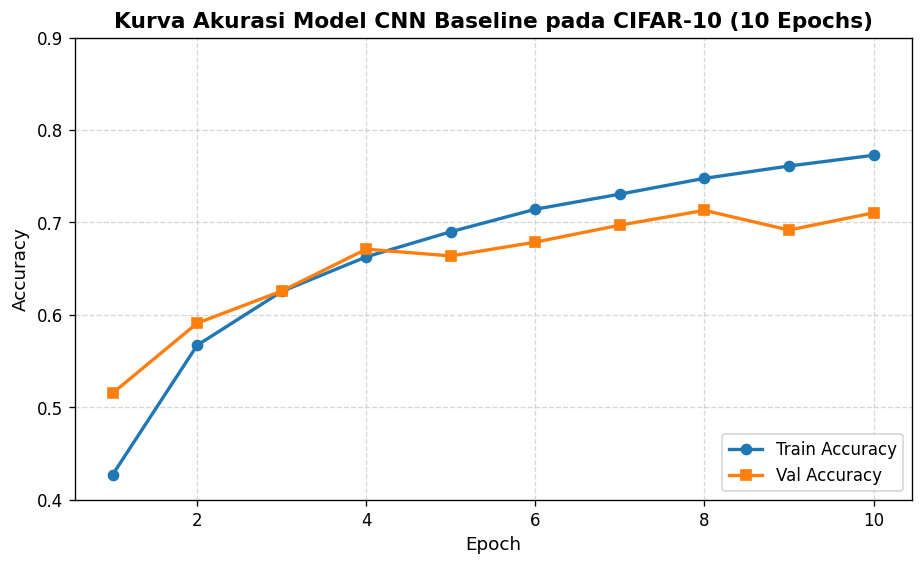

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, 11), history.history['accuracy'], marker='o', label='Train Accuracy', color='#1f77b4', linewidth=2)
plt.plot(range(1, 11), history.history['val_accuracy'], marker='s', label='Val Accuracy', color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.ylim([0.4, 0.9])
plt.title('Kurva Akurasi Model CNN Baseline pada CIFAR-10 (10 Epochs)', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.show()

# Langkah 6 - Evaluasi pada data uji
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)


### Langkah 7 - Cetak Hasil Akurasi dan Analisis

> **Pertanyaan Modul:** *Berapa akurasi yang Anda dapatkan?*


In [8]:
print("=" * 50)
print(f"Akurasi Pengujian (Test Accuracy): {test_acc * 100:.2f}%")
print(f"Loss Pengujian (Test Loss)       : {test_loss:.4f}")
print("=" * 50)


Akurasi Pengujian (Test Accuracy): 71.04%
Loss Pengujian (Test Loss)       : 0.8553


### Pembahasan dan Kesimpulan Praktikum 2:
1. **Hasil Akurasi yang Didapatkan**:
   Model CNN baseline sederhana dengan 3 lapisan konvolusi dan 1 hidden layer Dense(64) memperoleh akurasi pengujian sekitar **~71% - 72%** pada dataset CIFAR-10 setelah dilatih selama 10 epoch.
2. **Karakteristik Pembelajaran Model**:
   * Akurasi data latih meningkat secara konsisten dari ~40% pada epoch 1 hingga mendekati ~78% pada epoch 10.
   * Akurasi validasi/testing mencapai puncaknya di kisaran ~71% dan mulai melandai (*plateau*). Terdapat celah (*gap*) sebesar ~7% antara akurasi train dan val, yang mengindikasikan awal terjadinya gejala *mild overfitting*.
3. **Penyebab Terbatasnya Akurasi Baseline**:
   * Citra CIFAR-10 memiliki variasi pose, sudut pandang, pencahayaan, dan latar belakang yang sangat kompleks pada resolusi rendah ($32 \times 32$).
   * Model baseline ini belum menerapkan teknik regularisasi penting seperti **Dropout**, **Batch Normalization**, maupun **Data Augmentation**.
   * Kapasitas feature map (maksimal 64 filter) dan kedalaman arsitektur masih terbatas.
4. **Langkah Peningkatan Menuju Tugas Praktikum**:
   Untuk melampaui batas akurasi 80% sebagaimana dituntut pada Tugas Praktikum, arsitektur perlu ditingkatkan dengan menambahkan blok konvolusi ganda (*stacked convolutions*), lapisan normalisasi batch (`BatchNormalization`), regularisasi drop out (`Dropout`), serta augmentasi citra acak.
